# Did the April 2025 US Auto Tariff Move Korean Markets?
### An event study with a difference-in-differences comparison and placebo validation

**Summary:** Hyundai and Kia fell more than GM and Ford around the tariff date, with a market-adjusted Korea-minus-US gap of about **-2.38 percentage points**. The individual stock CAR tests are not significant, and 3 of 4 clean placebo dates produced gaps at least as large in magnitude. The gap shrinks as the window widens. These checks leave the tariff interpretation inconclusive; this notebook does not calculate a standard error or significance test for the group gap itself.

| Result | Value |
|---|---|
| Korea average CAR (Hyundai, Kia) | -3.30% |
| US average CAR (GM, Ford) | -0.92% |
| DiD (Korea minus US) | -2.38% |
| Individual CAR p-values | 0.43 to 0.95 (none significant) |
| Clean placebo DiD range | -2.62% to +3.91% |

*Data: Yahoo Finance (stock and index prices), FRED (KRW/USD, series DEXKOUS). The notebook reuses valid local raw CSVs and downloads missing or invalid inputs.*

## 1. Research question / Design

The US takes roughly 49% of Korea's auto exports (export-exposure figure from the Korean trade-policy documents collected for this project). **Research Question:** Did the US 25% tariff on autos and auto parts (effective **April 3, 2025**, Section 232) cause Korean automakers' stocks to move abnormally, beyond what the broad market explains, and is that reaction specific to Korea rather than a generic auto-sector shock? The tariff date was set in Washington for reasons unrelated to Hyundai's or Kia's own business, making it usable as a natural experiment. 

**Design.**
- **Treatment group:** Hyundai (005380.KS), Kia (000270.KS)
- **Comparison group:** GM, Ford
- **Method:** market-model event study (abnormal returns and cumulative abnormal returns) followed by difference-in-differences across the two groups, then placebo tests checking whether the design can tell a real event from noise.

**Other key dates in the project (not tested here):** The collected government documents provides key dates including April 9, 2025 (Korea's emergency auto package) and June 19, 2025 (KRW 30.5T supplementary budget). However, the main event window ends April 8, so it deliberately stops before April 9, when a global tariff pause moved all markets.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Jupyter has no __file__, so anchor on the notebook's working directory.
DATA_DIR = Path.cwd()

START, END = "2024-10-01", "2025-08-31"
EVENT_DATE = "2025-04-03"          # US 25% auto tariff takes effect
EST_START, EST_END = "2024-10-01", "2025-02-28"
WINDOW = 3                          # +/- 3 merged-calendar rows -> 7-date event window

TICKERS = {"hyundai": "005380.KS", "kia": "000270.KS", "gm": "GM",
           "ford": "F", "kospi": "^KS11", "sp": "^GSPC"}

## 2. Data

| Series | Source | Usage |
|---|---|---|
| Hyundai, Kia, GM, Ford daily prices | Yahoo Finance (`yfinance`) | stock returns |
| KOSPI (`^KS11`), S&P 500 (`^GSPC`) | Yahoo Finance | market benchmarks |
| KRW/USD (`DEXKOUS`) | FRED | exchange-rate series (collected but not analyzed in this version) |

Daily data, Oct 1, 2024 to Aug 29, 2025. Prices are Yahoo's default adjusted closes.

**Merging:** Each raw file calls its price column `Close`, so each is renamed before merging. Merged using **outer join** on date as Korean and US markets have different holidays (for instance, Korean markets were closed on 2024-10-01 while US markets were open) and an inner join would silently drop real data from the other side.
**Download handling:** `market_data.py` is shared with `econdata.py`. Valid cached CSVs are reused; missing or invalid inputs are fetched individually. Downloads are checked for expected columns, usable positive values, and unique, ordered dates within the requested period. FRED holiday gaps are allowed. Each replacement is written to a temporary file before replacing the destination; a failed download or write leaves existing files intact.


In [2]:
from market_data import download_raw

download_raw(DATA_DIR, TICKERS, START, END)
print("Raw CSVs validated; missing or invalid inputs downloaded.")


Raw CSVs validated; missing or invalid inputs downloaded.


In [3]:
# Load each file, keep Date + closing price, and give the price column a unique name
frames = []
for name in TICKERS:
    raw = pd.read_csv(DATA_DIR / f"{name}.csv", parse_dates=["Date"])
    frames.append(raw[["Date", "Close"]].rename(columns={"Close": name}))

fx = pd.read_csv(DATA_DIR / "fx.csv", parse_dates=["observation_date"])
frames.append(fx[["observation_date", "DEXKOUS"]].rename(columns={"observation_date": "Date", "DEXKOUS": "krw_usd"}))

price_cols = [*TICKERS, "krw_usd"]
# Use each series' previous observed session, before other markets add holiday rows.
for frame in frames:
    frame.sort_values("Date", inplace=True)
    col = frame.columns[1]
    observed = frame[col].dropna()
    frame[col + "_ret"] = np.log(observed / observed.shift(1))

# Outer join: Korean and US holidays differ, so keep every date from any file
m6 = frames[0]
for f in frames[1:]:
    m6 = m6.merge(f, on="Date", how="outer")
m6 = m6.sort_values("Date").reset_index(drop=True)
m6.to_csv(DATA_DIR / "merged_data.csv", index=False, columns=["Date", *price_cols])

print(m6.shape)
m6.head()


(239, 15)


,Date,hyundai,hyundai_ret,kia,kia_ret,gm,gm_ret,ford,ford_ret,kospi,kospi_ret,sp,sp_ret,krw_usd,krw_usd_ret
0,2024-10-01,NaN,NaN,NaN,NaN,44.028786,NaN,9.543482,NaN,NaN,NaN,5708.750000,NaN,1323.78,NaN
1,2024-10-02,219076.625000,NaN,88329.000000,NaN,43.969925,-0.001338,9.303783,-0.025437,2561.689941,NaN,5709.540039,0.000138,1321.53,-0.001701
2,2024-10-03,NaN,NaN,NaN,NaN,44.126888,0.003563,9.277152,-0.002867,NaN,NaN,5699.939941,-0.001683,1335.58,0.010575
3,2024-10-04,221387.562500,0.010493,87702.554688,-0.007117,44.813610,0.015443,9.383683,0.011418,2569.709961,0.003126,5751.069824,0.008930,1348.74,0.009805
4,2024-10-07,228320.359375,0.030835,89850.367188,0.024195,45.107918,0.006546,9.312662,-0.007597,2610.379883,0.015703,5695.939941,-0.009632,1343.75,-0.003707


In [4]:
# Made calendar mismatch visible: 2024-10-01, when Korean markets had one-day close off while US markets were open
m6[m6["Date"] == "2024-10-01"]

,Date,hyundai,hyundai_ret,kia,kia_ret,gm,gm_ret,ford,ford_ret,kospi,kospi_ret,sp,sp_ret,krw_usd,krw_usd_ret
0,2024-10-01,NaN,NaN,NaN,NaN,44.028786,NaN,9.543482,NaN,NaN,NaN,5708.75,NaN,1323.78,NaN


## 3. Log returns

For each series, the log return is `ln(current observed price / previous observed price)`. Returns are calculated on each series' own dates **before** the outer join. A closed-market date remains missing, but the next trading session retains its return since the previous observed session. Prices are not forward-filled, and the first observed price has no return.

For example, Korea was closed on October 3, 2024. Hyundai's October 4 return uses its October 2 close; Hyundai and KOSPI cover the same interval. US returns follow the US trading calendar. The checks below guard against dropping the Korean return on October 4.


In [5]:
# Regression check: the Korean holiday stays missing, but the next session has a return.
check = m6.set_index("Date")
assert pd.isna(check.loc["2024-10-03", "hyundai_ret"])
assert pd.isna(check.loc["2024-10-02", "hyundai_ret"])
np.testing.assert_allclose(
    check.loc["2024-10-04", ["hyundai_ret", "kospi_ret"]].to_numpy(dtype=float),
    np.log(check.loc["2024-10-04", ["hyundai", "kospi"]].to_numpy(dtype=float)
           / check.loc["2024-10-02", ["hyundai", "kospi"]].to_numpy(dtype=float)),
)

m6[["Date", "hyundai", "hyundai_ret", "kospi", "kospi_ret"]].head()


,Date,hyundai,hyundai_ret,kospi,kospi_ret
0,2024-10-01,NaN,NaN,NaN,NaN
1,2024-10-02,219076.625000,NaN,2561.689941,NaN
2,2024-10-03,NaN,NaN,NaN,NaN
3,2024-10-04,221387.562500,0.010493,2569.709961,0.003126
4,2024-10-07,228320.359375,0.030835,2610.379883,0.015703


## 4. Estimation window and Event window

- **Estimation window:** Oct 1, 2024 - Feb 28, 2025 (109 rows) A pre-tariff stretch was used only to learn each stock's *normal* relationship with its market.
- **Event window:** 7 merged-calendar dates centered on April 3, 2025 (March 31 - April 8). All four stocks and both benchmarks have returns on these dates. Other windows can include a holiday in one market; those missing returns are omitted for that market, so their session counts can differ.

Selected two windows that never overlap to ensure the event is unable to contaminate the model it is tested against.

In [6]:
est = m6[(m6["Date"] >= EST_START) & (m6["Date"] <= EST_END)]

event_idx = m6.index[m6["Date"] == EVENT_DATE][0]
event_window = m6.iloc[event_idx - WINDOW : event_idx + WINDOW + 1].copy()

print("Estimation window:", est.shape[0], "rows,", est["Date"].min().date(), "to", est["Date"].max().date())
print("Event window     :", event_window.shape[0], "rows")
print([d.isoformat() for d in event_window["Date"].dt.date])

Estimation window: 109 rows, 2024-10-01 to 2025-02-28
Event window     : 7 rows
['2025-03-31', '2025-04-01', '2025-04-02', '2025-04-03', '2025-04-04', '2025-04-07', '2025-04-08']


## 5. The market model

For each stock, an OLS regression was applied on the estimation window only:

$$r_{stock,t} = \alpha + \beta \, r_{market,t} + \varepsilon_t$$

Hyundai and Kia are regressed on KOSPI; GM and Ford on the S&P 500 (each stock against *its own* home market). Using `alpha`: average return on a day the market does not move; `beta`: stock's sensitivity to the market. The fitted line reveals stock's normal behavior (what it should have returned given what market did that day).

In [7]:
# Which market benchmark applies to which stock
MARKET = {"hyundai": "kospi_ret", "kia": "kospi_ret", "gm": "sp_ret", "ford": "sp_ret"}

models = {}
for asset, mkt in MARKET.items():
    X = sm.add_constant(est[mkt])
    models[asset] = sm.OLS(est[asset + "_ret"], X, missing="drop").fit()

summary = pd.DataFrame({
    a: {"alpha": m.params["const"], "alpha p-value": m.pvalues["const"],
        "beta": m.params[MARKET[a]], "beta p-value": m.pvalues[MARKET[a]],
        "R-squared": m.rsquared, "n obs": int(m.nobs)}
    for a, m in models.items()
}).T
summary.round(4)

,alpha,alpha p-value,beta,beta p-value,R-squared,n obs
hyundai,-0.0017,0.3435,0.9415,0.0000,0.2713,98.0
kia,-0.0005,0.7800,0.9826,0.0000,0.3093,98.0
gm,0.0006,0.8079,0.8317,0.0045,0.0778,102.0
ford,-0.0010,0.5817,0.7963,0.0009,0.1047,102.0


**Reading Table:** Hyundai's beta (0.94) and Kia's (0.98) are close to one, indicating that they tend to move with KOSPI. GM (0.83) and Ford (0.80) are also significantly related to the S&P 500. Alpha is not statistically distinguishable from zero for any stock.

R-squared is about 27% for Hyundai, 31% for Kia, 8% for GM, and 10% for Ford. Much of each stock's daily variation remains unexplained by the market model.

Calculating returns before merging retains valid sessions after holidays: the estimation samples now contain 98 observations for each Korean stock and 102 for each US stock. This step fits the normal relationship with the home market; it does not test the tariff effect.

In [8]:
def event_stats(asset, center_date, window=WINDOW):
    """Abnormal returns, CAR, t-stat and p-value for one stock around center_date."""
    m, mkt = models[asset], MARKET[asset]
    idx = m6.index[m6["Date"] == center_date][0]
    w = m6.iloc[idx - window : idx + window + 1]
    expected = m.params["const"] + m.params[mkt] * w[mkt]
    abnormal = w[asset + "_ret"] - expected
    car = abnormal.sum()
    se = m.resid.std() * np.sqrt(abnormal.notna().sum())
    t = car / se
    p = 2 * (1 - stats.t.cdf(abs(t), m.df_resid))
    return {"CAR": car, "t-stat": t, "p-value": p, "abnormal": abnormal}

real = {a: event_stats(a, EVENT_DATE) for a in MARKET}
car_table = pd.DataFrame({a: {k: v for k, v in r.items() if k != "abnormal"} for a, r in real.items()}).T
car_table["group"] = ["Korea", "Korea", "US", "US"]
car_table.round(4)

,CAR,t-stat,p-value,group
hyundai,-0.0365,-0.7930,0.4297,Korea
kia,-0.0294,-0.6707,0.5040,Korea
gm,-0.0040,-0.0642,0.9489,US
ford,-0.0144,-0.2884,0.7736,US


## 6. Abnormal returns and CAR

On each event-window day, **abnormal return = actual return - (alpha + beta x market return)**. Sum over 7 days is shown as **cumulative abnormal return (CAR)**. Its significance test is

$$t = \frac{CAR}{\hat\sigma_\varepsilon \sqrt{n}}$$

where the residual standard deviation comes from the estimation-window regression and n = number of event days.

**Reading Table:** All four CARs are negative: Hyundai -3.65%, Kia -2.94%, GM -0.40%, and Ford -1.44%. Their individual CAR p-values range from 0.43 to 0.95, so none rejects zero at the 5% level. These individual tests do not establish the significance of the Korea-minus-US difference.

## 7. Difference-in-differences (DID)

The average Korean CAR minus the average US CAR is a descriptive measure of relative performance. Interpreting it as a Korea-specific tariff effect requires assumptions about shared shocks and the comparison group. This notebook reports the gap without its own standard error or formal significance test.

In [9]:
korea_avg = np.mean([real["hyundai"]["CAR"], real["kia"]["CAR"]])
us_avg = np.mean([real["gm"]["CAR"], real["ford"]["CAR"]])
did_real = korea_avg - us_avg

print(f"Korea average CAR : {korea_avg:+.4f}")
print(f"US average CAR    : {us_avg:+.4f}")
print(f"DiD (Korea - US)  : {did_real:+.4f}")

Korea average CAR : -0.0330
US average CAR    : -0.0092
DiD (Korea - US)  : -0.0238


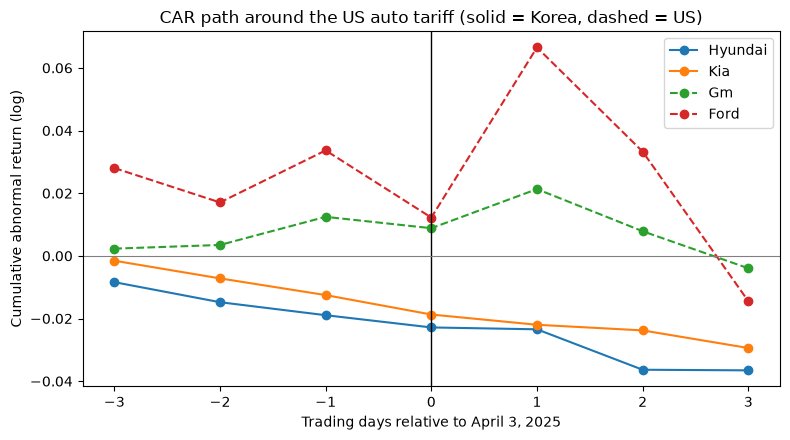

In [10]:
# Cumulative abnormal return path across the event window
fig, ax = plt.subplots(figsize=(8, 4.5))
rel_days = list(range(-WINDOW, WINDOW + 1))
for a in MARKET:
    ax.plot(rel_days, real[a]["abnormal"].cumsum().values, marker="o", label=a.capitalize(),
            linestyle="-" if a in ("hyundai", "kia") else "--")
ax.axvline(0, color="black", linewidth=1)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Trading days relative to April 3, 2025")
ax.set_ylabel("Cumulative abnormal return (log)")
ax.set_title("CAR path around the US auto tariff (solid = Korea, dashed = US)")
ax.legend()
fig.tight_layout()
fig.savefig(DATA_DIR / "car_paths.png", dpi=150)
plt.show()

## 8. Placebo test: can this design tell a real event from noise?

The identical procedure is rerun on dates when no tariff news occurred. We assume real DiD can't be told apart from noise if random dates produce DiDs as large as the real one.

In the result, **one date (2024-10-21) was excluded after investigation**, producing a far larger DiD of -12.5%. GM rose **+9.4% on 2024-10-22** (almost certainly its Q3 earnings release) in the day-by-day table below. As a real, company-specific event, the date is not a valid "nothing happened" placebo; it's shown for transparency but excluded from the comparison. To ensure placebo date is quiet for *every* firm in the test, the early-December 2024 Korean martial-law crisis and the US election week were avoided for the same reason.

In [11]:
def did_at(center_date, window=WINDOW):
    r = {a: event_stats(a, center_date, window)["CAR"] for a in MARKET}
    return (r["hyundai"] + r["kia"]) / 2 - (r["gm"] + r["ford"]) / 2

placebo_dates = {
    "2024-10-21": "contaminated (GM Q3 earnings 2024-10-22)",
    "2024-11-19": "clean",
    "2025-01-08": "clean",
    "2025-01-15": "clean",
    "2025-02-05": "clean",
}
placebo = pd.DataFrame({"DiD": {d: did_at(d) for d in placebo_dates}, "status": placebo_dates})
placebo.round(4)

,DiD,status
2024-10-21,-0.1252,contaminated (GM Q3 earnings 2024-10-22)
2024-11-19,0.0383,clean
2025-01-08,0.0151,clean
2025-01-15,-0.0262,clean
2025-02-05,0.0391,clean


In [12]:
# Why 2024-10-21 is excluded: one single-day move dominates the window
idx = m6.index[m6["Date"] == "2024-10-21"][0]
m6.iloc[idx - WINDOW : idx + WINDOW + 1][["Date", "hyundai_ret", "kia_ret", "gm_ret", "ford_ret", "kospi_ret", "sp_ret"]].round(4)

notebook_cell_21:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.


,Date,hyundai_ret,kia_ret,gm_ret,ford_ret,kospi_ret,sp_ret
11,2024-10-16,0.0041,-0.0192,0.0240,0.0174,-0.0088,0.0047
12,2024-10-17,-0.0477,-0.0269,0.0075,0.0036,-0.0004,-0.0002
13,2024-10-18,-0.0043,-0.0011,-0.0041,0.0027,-0.0060,0.0040
14,2024-10-21,0.0106,-0.0011,-0.0051,-0.0200,0.0043,-0.0018
15,2024-10-22,-0.0106,-0.0267,0.0936,0.0209,-0.0132,-0.0005
16,2024-10-23,0.0273,0.0054,-0.0152,-0.0045,0.0112,-0.0092
17,2024-10-24,-0.0533,-0.0228,-0.0038,0.0161,-0.0072,0.0021


Real-event DiD          : -0.0238
Clean placebo DiD range : -0.0262 to +0.0391
Placebos with |DiD| >= |real DiD|: 3 of 4


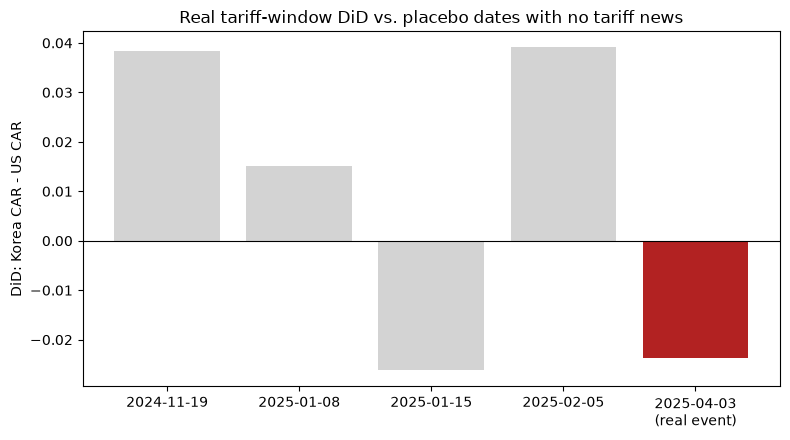

In [13]:
clean = placebo[placebo["status"] == "clean"]["DiD"].astype(float)
print(f"Real-event DiD          : {did_real:+.4f}")
print(f"Clean placebo DiD range : {clean.min():+.4f} to {clean.max():+.4f}")
print(f"Placebos with |DiD| >= |real DiD|: {(clean.abs() >= abs(did_real)).sum()} of {len(clean)}")

fig, ax = plt.subplots(figsize=(8, 4.5))
labels = list(clean.index) + ["2025-04-03\n(real event)"]
vals = list(clean.values) + [did_real]
colors = ["lightgray"] * len(clean) + ["firebrick"]
ax.bar(labels, vals, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("DiD: Korea CAR - US CAR")
ax.set_title("Real tariff-window DiD vs. placebo dates with no tariff news")
fig.tight_layout()
fig.savefig(DATA_DIR / "placebo_did.png", dpi=150)
plt.show()

**Reading Placebo result:** The real-event DiD (-2.38%) lies inside the clean placebo range (-2.62% to +3.91%). Three of the four clean placebos have a gap at least as large in magnitude; January 8 is smaller. Three point the opposite way, with Korea outperforming. This is a descriptive comparison of four selected dates, not a formal significance test for the group gap.

## 9. Checking robustness with different window widths

In [14]:
rows = []
for w in [1, 2, 3, 5]:
    cars = {a: event_stats(a, EVENT_DATE, w) for a in MARKET}
    d = (cars["hyundai"]["CAR"] + cars["kia"]["CAR"]) / 2 - (cars["gm"]["CAR"] + cars["ford"]["CAR"]) / 2
    rows.append({"window": f"[-{w},+{w}]", "Hyundai CAR": cars["hyundai"]["CAR"], "Kia CAR": cars["kia"]["CAR"],
                 "GM CAR": cars["gm"]["CAR"], "Ford CAR": cars["ford"]["CAR"], "DiD": d,
                 "min p-value": min(c["p-value"] for c in cars.values())})
pd.DataFrame(rows).set_index("window").round(4)

,Hyundai CAR,Kia CAR,GM CAR,Ford CAR,DiD,min p-value
window,,,,,,
"[-1,+1]",-0.0087,-0.0148,0.0178,0.0495,-0.0454,0.1344
"[-2,+2]",-0.0280,-0.0222,0.0056,0.0052,-0.0305,0.4745
"[-3,+3]",-0.0365,-0.0294,-0.0040,-0.0144,-0.0238,0.4297
"[-5,+5]",-0.0794,-0.0574,-0.0917,-0.0436,-0.0008,0.1723


**Reading Robustness Table:** The DiD stays negative but changes substantially in size: -4.54% at [-1,+1], -3.05% at [-2,+2], -2.38% at [-3,+3], -0.08% at [-5,+5]. It is close to zero at [-5,+5], so its magnitude is sensitive to the window. The smallest individual-stock CAR p-value across these windows is 0.13; these are not p-values for the group gap. The [-5,+5] window also reaches April 9-10, when the global tariff pause moved markets, so it is the least clean of the four.

## 10. Discussion

**What the evidence supports:** Korean automakers underperformed US automakers by 2.38 percentage points in the main window after adjustment for each home market. None of the individual stock CAR tests rejects zero at the 5% level. Three of four clean placebo gaps are at least as large in magnitude, and the real-event gap shrinks toward zero as the window widens. These checks make the tariff interpretation inconclusive. Because the group gap has no formal test here, they do not establish that the gap itself is statistically insignificant.

This does not show that the tariff had no effect. The small number of firms, selected placebo dates, and overlapping news limit what this design can establish.

**Limitations:**
1. **Small N:** Two treated and two comparison firms, with a single event. This is the main source of low power.
2. **The comparison group is not untreated:** GM and Ford also face tariff costs through imported parts and Canadian/Mexican production, so the DiD measures a *relative* effect and likely understates the Korea-specific one.
3. **Confounding news in the window:** The tariff was announced in late March, so part of the reaction predates the window, and the broader reciprocal-tariff announcement came on April 2, one day before the event date.
4. **Placebos are in-sample:** The placebo dates fall inside the estimation window used to fit the market model, and there are only four clean ones. Excluding the contaminated date was a judgement made after seeing its result, which I flagged rather than hid.
5. **Statistical assumptions:** Standard errors assume independent, roughly normal residuals and the 7 event days are summed assuming independence. Stock returns typically have fatter tails than a normal distribution, which this notebook does not test for.
6. **Exchange rate not analyzed:** The KRW/USD series is collected and merged, but this version does not test it: there is no natural equivalent of a market index for a currency, so it needs a different benchmark design.
7. **Trading calendars:** Each return spans that series' previous observed session, so a Korean stock and KOSPI remain aligned after a Korean holiday. US returns follow their own calendar. Windows are selected from the merged date index; some placebo or robustness windows can contain different numbers of valid sessions across markets. Missing holiday prices are not forward-filled.

## 11. Conclusion

**Conclusion:** Around the April 3, 2025 US auto tariff, Hyundai and Kia underperformed GM and Ford by about 2.38 percentage points after home-market adjustment in the 7-date event window. The individual stock CARs are not significant at the 5% level, three of four selected clean placebos have gaps at least as large in magnitude, and the gap approaches zero in the widest window. The relative tariff effect remains inconclusive; a formal test of the group gap is still needed.

**Next steps/Revision:** 

Possible methods to improve the research could be 
1. Adding firms across sectors with different US-export exposure (like steel, batteries, semiconductors, using the sector exposure figures in the Korean government's trade-policy documents) and regress abnormal returns on exposure in a cross-section. This uses variation across many firms instead of a few days.
2. Running full distribution in many placebo dates instead of a 1-1 comparison.
3. Formal DiD regression with a treated x post interaction and robust or clustered standard errors, to give DiD its own standard error.
4. Analysis on the KRW/USD series against a basket of other Asian currencies as the benchmark.
5. Study on the policy responses as separate events (April 9 package, June 19 supplementary budget).